# GATv2 — Recipe Tuning on Config 2 (HI-Small)

- **Question:** which training recipe (dropout, normalisation, depth, FFN, self-loops, class weight, learning rate) should the GATv2 family use? Tuned **once** here on config 2 (mp base / readout base), then frozen for every GATv2 feature config.
- **Protocol (`EXPERIMENTS.md` §2b, fixed in advance):** one knob at a time in a pre-registered order — norm → layers → FFN → self-loops → pos_weight → learning rate → dropout (architecture first, then optimizer, regularisation last; the self-loop stage is GATv2's own knob, PyG's `add_self_loops`, on in v1) — starting from the v1 recipe; one seed per trial (42; budget decision, the seed std is 0 so the winner margin is the fixed 0.01), selection on validation only, cosine T_max 100 with early stopping, best epoch from the smoothed validation curve; a trial replaces the incumbent only if it beats it by more than max(0.01, the larger seed std); the edge rule adds one trial one step beyond a winner at the edge of its grid.
- **Everything shared** lives in `gnn_core.py` (`run_tuning_trial`, `choose_winner`, `probe_depths`, `save_recipe`). This notebook only sets the operator, the stages and paths.
- **Never touches test:** only train and validation loaders are built, no `predictions.csv`. **Resumable:** a finished trial (`trial.json` committed in the repo) is skipped, so stages can span Kaggle sessions.

## 0. Environment (Kaggle)

- Pinned PyTorch / PyG stack known to work on Kaggle GPU — do not change versions or order.
- Then clone (or pull) the public repo so the committed `gnn_core.py` is the one imported.

In [1]:
!pip uninstall -y torch torchvision torchaudio torch-scatter torch-sparse pyg_lib
!pip install torch==2.8.0 torchvision torchaudio --index-url https://download.pytorch.org/whl/cu126
!pip install torch-scatter torch-sparse torch-cluster -f https://data.pyg.org/whl/torch-2.8.0+cu126.html
!pip install torch_geometric

Found existing installation: torch 2.11.0+cu128
Uninstalling torch-2.11.0+cu128:
  Successfully uninstalled torch-2.11.0+cu128
Found existing installation: torchvision 0.26.0+cu128
Uninstalling torchvision-0.26.0+cu128:
  Successfully uninstalled torchvision-0.26.0+cu128
Found existing installation: torchaudio 2.11.0+cu128
Uninstalling torchaudio-2.11.0+cu128:
  Successfully uninstalled torchaudio-2.11.0+cu128
Looking in indexes: https://download.pytorch.org/whl/cu126
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.7/23.7 MB 98.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 897.7/897.7 kB 240.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 193.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 706.8/706.8 MB 63.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 393.1/393.1 MB 82.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 200.2/200.2 MB 124.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [2]:
import os
import sys

REPO_URL = 'https://github.com/sandrokhizanishvili/gnn_for_fraudulent_patterns.git'
REPO_DIR = '/kaggle/working/gnn_for_fraudulent_patterns'
if os.path.isdir(REPO_DIR):
    !git -C {REPO_DIR} pull
else:
    !git clone {REPO_URL} {REPO_DIR}
!git -C {REPO_DIR} log -1 --oneline
sys.path.append(REPO_DIR)

Cloning into '/kaggle/working/gnn_for_fraudulent_patterns'...
remote: Enumerating objects: 898, done.
remote: Counting objects: 100% (898/898), done.
remote: Compressing objects: 100% (758/758), done.
remote: Total 898 (delta 277), reused 736 (delta 122), pack-reused 0 (from 0)
Receiving objects: 100% (898/898), 32.16 MiB | 15.56 MiB/s, done.
Resolving deltas: 100% (277/277), done.
3d13d19 (HEAD -> main, origin/main, origin/HEAD) GBT: tail-window side check as a labelled notebook appendix


## 1. Configuration

- `STAGES`: the pre-registered knob order and grids; the winner of each stage is carried into the next.
- `TUNE`: the only change to the v1 recipe before tuning starts — cosine length 100 (early stopping decides the run length).
- `OUT_ROOT` sits **inside the repo clone**, so trials committed after an earlier session are found and skipped.

In [3]:
OPERATOR = 'gat'
CFG      = dict(mp='base', readout='base')     # config 2 — the configuration every recipe is tuned on
SEEDS    = (42,)                                # one tuning seed per trial (budget decision); the final retrain uses 42-45
TUNE     = dict(epochs=100)                     # v1 recipe + cosine T_max 100; nothing else changes before stage 1

# one knob at a time, architecture first, then optimizer, regularisation last (EXPERIMENTS.md section 2b);
# the incumbent value is in every grid, so the v1 recipe is the starting incumbent
STAGES = [
    ('s1_norm',       'norm',       ['none', 'batch', 'layer']),
    ('s2_layers',     'num_layers', [2, 4, 6]),
    ('s3_ffn',        'ffn',        [False, True]),
    ('s4_self_loops', 'self_loops', [True, False]),    # GATv2 only: PyG add_self_loops (v1 = on)
    ('s5_pos_weight', 'pos_weight', [8.0, 16.0]),
    ('s6_lr',         'lr',         [5e-4, 1e-3, 3e-3]),
    ('s7_dropout',    'dropout',    [0.2, 0.3, 0.4]),
]
PATIENCE, MIN_EPOCHS, EVAL_TRAIN_EVERY = 10, 20, 5   # early stopping on the smoothed val F1; train scored every 5th epoch
PROBE_DEPTHS = (2, 4, 6)                             # heaviest setting (BatchNorm + FFN) probed before stage 1

MP_DIRECTION      = 'in'     # fixed for the whole tuning
TEMPORAL_SAMPLING = False

# paths — OUT_ROOT inside the repo clone so committed trials resume
DATA_DIR = '/kaggle/input/datasets/sandrokhizanishvili/hi-small-gnn'
OUT_ROOT = f'{REPO_DIR}/Outputs/TUNING/{OPERATOR.upper()}'

import gnn_core as core
os.makedirs(OUT_ROOT, exist_ok=True)
print(f'torch {core.torch.__version__} | device {core.device} | gnn_core from {core.__file__}')
print(f'v1 recipe {core.full_recipe(None)}')
print(f'tuning starts from {core.full_recipe(TUNE)}')

torch 2.8.0+cu126 | device cuda | gnn_core from /kaggle/working/gnn_for_fraudulent_patterns/gnn_core.py
v1 recipe {'hidden': 128, 'num_layers': 2, 'dropout': 0.3, 'norm': 'none', 'ffn': False, 'num_neighbors': [100, 100], 'batch_size': 8192, 'epochs': 20, 'lr': 0.001, 'weight_decay': 1e-05, 'pos_weight': 8.0, 'self_loops': True}
tuning starts from {'hidden': 128, 'num_layers': 2, 'dropout': 0.3, 'norm': 'none', 'ffn': False, 'num_neighbors': [100, 100], 'batch_size': 8192, 'epochs': 100, 'lr': 0.001, 'weight_decay': 1e-05, 'pos_weight': 8.0, 'self_loops': True}


## 2. Load graphs

- Three cumulative PyG snapshots; context edges carry label −1, only `eval_mask` edges are scored.
- Only train and validation are used here; the test snapshot is loaded (same loader as every notebook) but never read.

In [4]:
graphs, col_sets, node_dim = core.load_graphs(DATA_DIR)

edge_attr width 81 (base 20 + gfp 61, variant v0)
train nodes=515,070 edges=3,046,342 evaluated=3,046,342 laundering=2,297 (0.0754%)
val   nodes=515,070 edges=4,061,789 evaluated=1,015,447 laundering=1,082 (0.1066%)
test  nodes=515,070 edges=5,077,237 evaluated=1,015,448 laundering=1,143 (0.1126%)


## 3. Probe — memory and time per depth

- Per depth (2 / 4 / 6) at the heaviest setting (BatchNorm + FFN): 3 warm-up batches, 20 timed training batches with peak GPU memory, then one full prediction pass over the validation graph.
- A depth passes when it fits and its epoch estimate is ≤ 3× the 2-layer one; otherwise the far-hop fallback list is tried, then the depth is dropped.
- `NEIGHBOURS_USED` is what the stages run with; the full record goes to `probe.json`.

In [5]:
HEAVIEST = dict(TUNE, norm='batch', ffn=True)
probe = core.probe_depths(OPERATOR, CFG, graphs, col_sets, node_dim, HEAVIEST, PROBE_DEPTHS,
                          f'{OUT_ROOT}/probe.json', mp_direction=MP_DIRECTION, temporal=TEMPORAL_SAMPLING)
NEIGHBOURS_USED = core.neighbours_from_probe(probe)
print('neighbour lists used:', NEIGHBOURS_USED)

--- probe: 2 layers, primary neighbours [100, 100]


/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


predict probe val 2L:   0%|          | 0/124 [00:00<?, ?it/s]

    train 0.11 s/batch x 372 = 0.7 min, peak 1.8 GB | val pass 0.2 min, peak 1.2 GB | epoch ~0.9 min (1.00x the first depth)
--- probe: 4 layers, primary neighbours [100, 100, 50, 50]


predict probe val 4L:   0%|          | 0/124 [00:00<?, ?it/s]

    train 0.32 s/batch x 372 = 2.0 min, peak 5.1 GB | val pass 0.5 min, peak 2.0 GB | epoch ~2.5 min (2.86x the first depth)
--- probe: 6 layers, primary neighbours [100, 100, 50, 50, 25, 25]


predict probe val 6L:   0%|          | 0/124 [00:00<?, ?it/s]

    train 0.56 s/batch x 372 = 3.5 min, peak 8.4 GB | val pass 0.9 min, peak 2.3 GB | epoch ~4.4 min (4.94x the first depth)
    too slow: 4.94x > 3.0x
--- probe: 6 layers, fallback neighbours [100, 100, 25, 25, 10, 10]


predict probe val 6L:   0%|          | 0/124 [00:00<?, ?it/s]

    train 0.55 s/batch x 372 = 3.4 min, peak 8.1 GB | val pass 1.1 min, peak 2.1 GB | epoch ~4.5 min (5.08x the first depth)
    too slow: 5.08x > 3.0x
probe: {2: 'ok (primary)', 4: 'ok (primary)', 6: 'dropped'} -> /kaggle/working/gnn_for_fraudulent_patterns/Outputs/TUNING/GAT/probe.json
neighbour lists used: {2: [100, 100], 4: [100, 100, 50, 50]}


## 4. Run the stages

- Per stage: one trial per grid value (both seeds back to back, then the post-trial scoring → `trial.json`), the winner by the pre-registered rule, the edge rule if the winner sits at the grid edge, then the winner becomes the incumbent.
- The incumbent's recipe is never retrained in a later stage: its scoring is copied into that stage.
- An edge-rule depth (3 or 8) is probed first and runs only if it passes.
- Per-epoch line: train / val loss, F1 (train at the val threshold, every 5th epoch), PR-AUC, seconds, RAM; `* new best` marks the checkpoint.

=== s1_norm/base === already finished (val F1 0.5488 ± 0.0000, best epoch 44), skipping
=== s1_norm/bn === already finished (val F1 0.5545 ± 0.0000, best epoch 31), skipping
=== s1_norm/ln === already finished (val F1 0.5505 ± 0.0000, best epoch 44), skipping
winner: base (val F1 0.5488 ± 0.0000); incumbent base 0.5488 ± 0.0000
3 trials -> /kaggle/working/gnn_for_fraudulent_patterns/Outputs/TUNING/GAT/s1_norm/stage_summary.csv | train - val gap: validation has 0.107 % laundering vs 0.075 % on train, so part of the gap is prevalence, not underfitting
>>> after s1_norm: incumbent = base | best epoch 44 | {'hidden': 128, 'num_layers': 2, 'dropout': 0.3, 'norm': 'none', 'ffn': False, 'num_neighbors': [100, 100], 'batch_size': 8192, 'epochs': 100, 'lr': 0.001, 'weight_decay': 1e-05, 'pos_weight': 8.0, 'self_loops': True}
=== s2_layers/base === already finished (val F1 0.5488 ± 0.0000, best epoch 44), skipping
=== s2_layers/l4 === already finished (val F1 0.5395 ± 0.0000, best epoch 49), ski

predict probe val 3L:   0%|          | 0/124 [00:00<?, ?it/s]

    train 0.22 s/batch x 372 = 1.4 min, peak 3.4 GB | val pass 0.4 min, peak 1.7 GB | epoch ~1.8 min (1.98x the first depth)
probe: {3: 'ok (primary)'} -> /kaggle/working/gnn_for_fraudulent_patterns/Outputs/TUNING/GAT/probe_3L.json
=== s2_layers/l3 === already finished (val F1 0.5395 ± 0.0000, best epoch 43), skipping
winner: base (val F1 0.5488 ± 0.0000); incumbent base 0.5488 ± 0.0000
3 trials -> /kaggle/working/gnn_for_fraudulent_patterns/Outputs/TUNING/GAT/s2_layers/stage_summary.csv | train - val gap: validation has 0.107 % laundering vs 0.075 % on train, so part of the gap is prevalence, not underfitting
>>> after s2_layers: incumbent = base | best epoch 44 | {'hidden': 128, 'num_layers': 2, 'dropout': 0.3, 'norm': 'none', 'ffn': False, 'num_neighbors': [100, 100], 'batch_size': 8192, 'epochs': 100, 'lr': 0.001, 'weight_decay': 1e-05, 'pos_weight': 8.0, 'self_loops': True}
=== s3_ffn/base === already finished (val F1 0.5488 ± 0.0000, best epoch 44), skipping
=== s3_ffn/ffn === al

train:   0%|          | 0/372 [00:00<?, ?it/s]

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

...

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 50 | loss 0.0083 / 0.0115 | F1 0.4992 / 0.5330 @ 0.386 | PR-AUC 0.4498 / 0.4613 | 104s | RAM 7.8GB   (train / val)


train:   0%|          | 0/372 [00:00<?, ?it/s]

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 51 | loss   -    / 0.0116 | F1   -    / 0.5364 @ 0.377 | PR-AUC   -    / 0.4676 | 66s | RAM 7.8GB   (train / val)
early stop at epoch 51: smoothed val F1 has not improved for 10 epochs
best validation F1 0.5433 at epoch 40 (threshold 0.271) | 51 of 100 epochs run


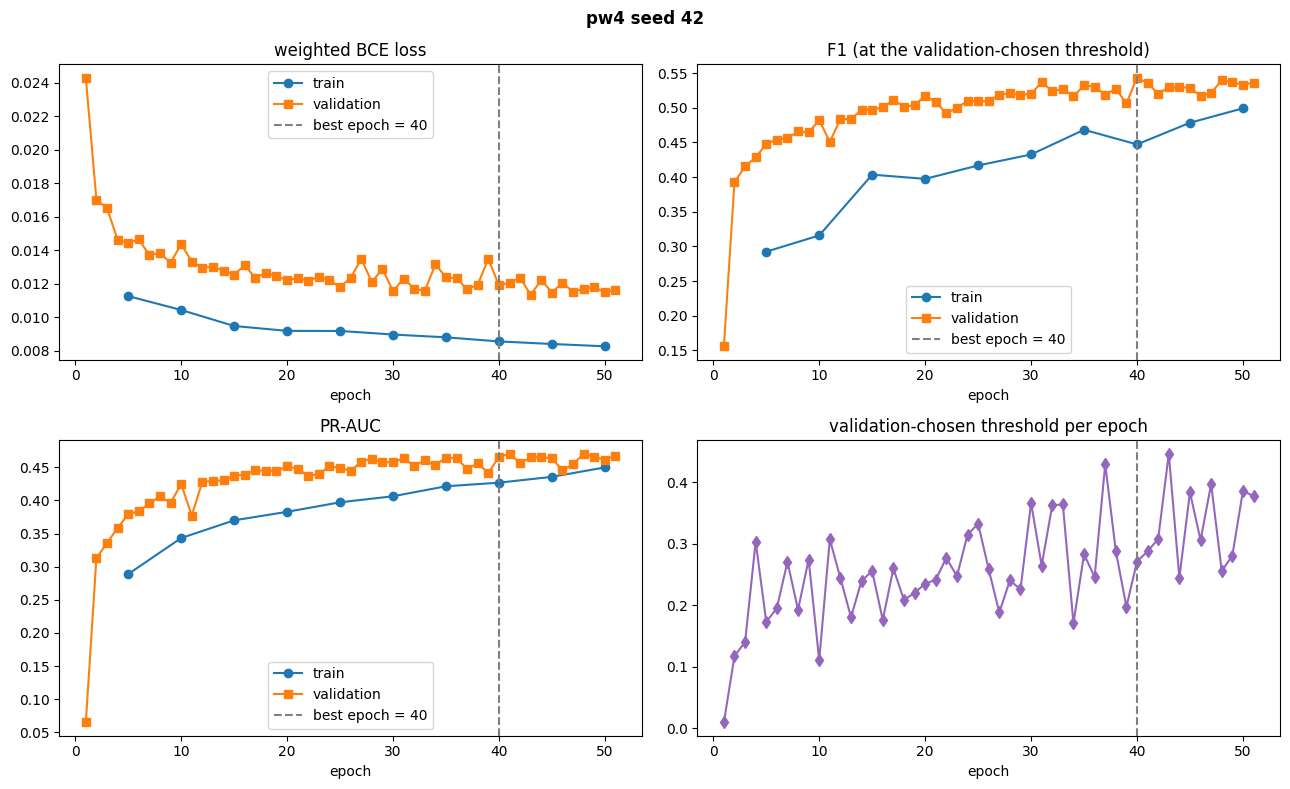

/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


predict train seed 42 @ epoch 49:   0%|          | 0/372 [00:00<?, ?it/s]

predict val seed 42 @ epoch 49:   0%|          | 0/124 [00:00<?, ?it/s]

trial pw4: best epoch 49 (seed-mean, smoothed) | val F1 0.5362 ± 0.0000 | train F1 0.4902 | gap -0.0460 | epochs run {'42': 51} | checkpoints deleted
winner: base (val F1 0.5488 ± 0.0000); incumbent base 0.5488 ± 0.0000
3 trials -> /kaggle/working/gnn_for_fraudulent_patterns/Outputs/TUNING/GAT/s5_pos_weight/stage_summary.csv | train - val gap: validation has 0.107 % laundering vs 0.075 % on train, so part of the gap is prevalence, not underfitting
>>> after s5_pos_weight: incumbent = base | best epoch 44 | {'hidden': 128, 'num_layers': 2, 'dropout': 0.3, 'norm': 'none', 'ffn': False, 'num_neighbors': [100, 100], 'batch_size': 8192, 'epochs': 100, 'lr': 0.001, 'weight_decay': 1e-05, 'pos_weight': 8.0, 'self_loops': True}
=== s6_lr/lr0.0005 === recipe {'hidden': 128, 'num_layers': 2, 'dropout': 0.3, 'norm': 'none', 'ffn': False, 'num_neighbors': [100, 100], 'batch_size': 8192, 'epochs': 100, 'lr': 0.0005, 'weight_decay': 1e-05, 'pos_weight': 8.0, 'self_loops': True}
=== lr0.0005 seed 42 

/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


...

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 50 | loss 0.0136 / 0.0186 | F1 0.4634 / 0.5170 @ 0.604 | PR-AUC 0.4496 / 0.4616 | 104s | RAM 7.6GB   (train / val)


train:   0%|          | 0/372 [00:00<?, ?it/s]

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 51 | loss   -    / 0.0196 | F1   -    / 0.5229 @ 0.501 | PR-AUC   -    / 0.4608 | 67s | RAM 7.6GB   (train / val)
early stop at epoch 51: smoothed val F1 has not improved for 10 epochs
best validation F1 0.5358 at epoch 41 (threshold 0.557) | 51 of 100 epochs run


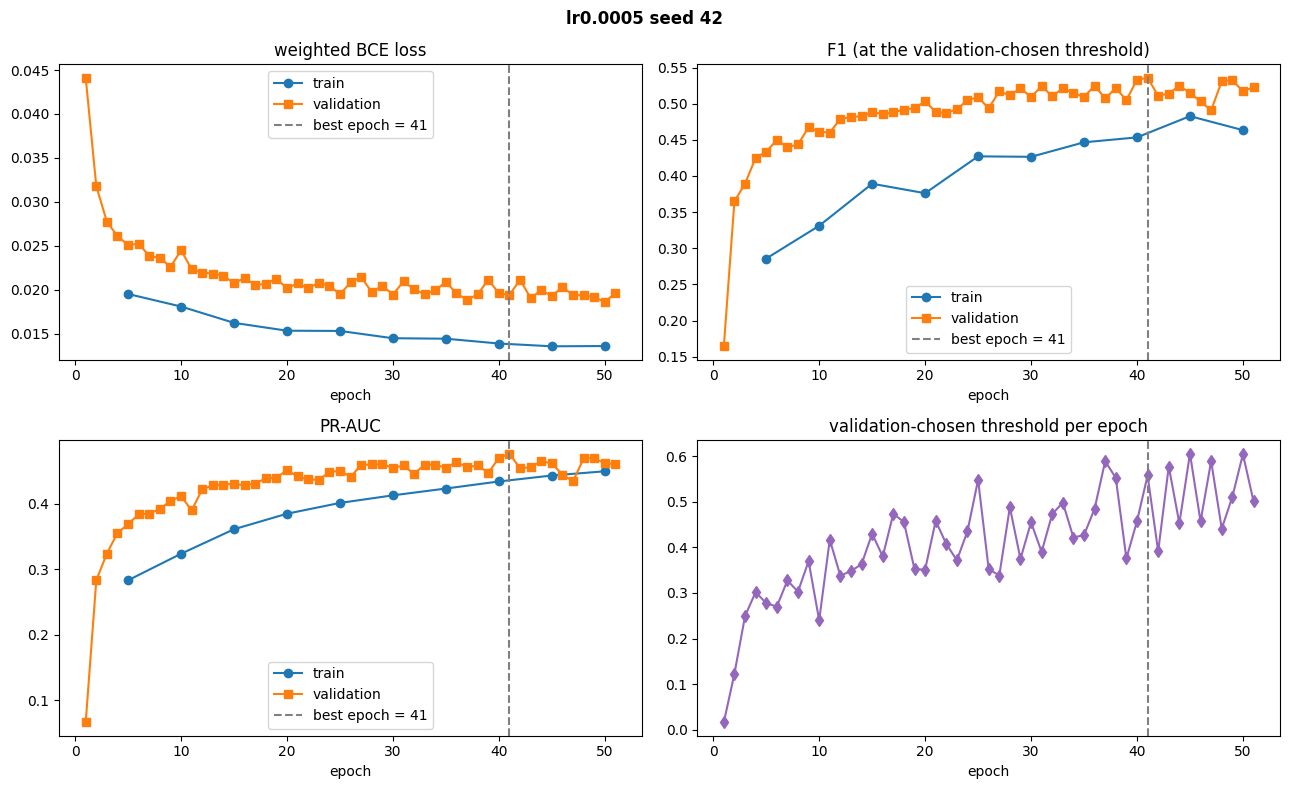

/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


predict train seed 42 @ epoch 49:   0%|          | 0/372 [00:00<?, ?it/s]

predict val seed 42 @ epoch 49:   0%|          | 0/124 [00:00<?, ?it/s]

trial lr0.0005: best epoch 49 (seed-mean, smoothed) | val F1 0.5308 ± 0.0000 | train F1 0.4732 | gap -0.0576 | epochs run {'42': 51} | checkpoints deleted
=== s6_lr/base === same recipe as the incumbent s5_pos_weight/base: scoring copied, not retrained
=== s6_lr/lr0.003 === recipe {'hidden': 128, 'num_layers': 2, 'dropout': 0.3, 'norm': 'none', 'ffn': False, 'num_neighbors': [100, 100], 'batch_size': 8192, 'epochs': 100, 'lr': 0.003, 'weight_decay': 1e-05, 'pos_weight': 8.0, 'self_loops': True}
=== lr0.003 seed 42 ===
MP edge features: 20 | readout edge features: 20 | node features: 6
total params: 108,161 | architecture-invariant: 67,585


/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


...

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 71 | loss   -    / 0.0202 | F1   -    / 0.5270 @ 0.397 | PR-AUC   -    / 0.4532 | 67s | RAM 7.6GB   (train / val)


train:   0%|          | 0/372 [00:00<?, ?it/s]

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 72 | loss   -    / 0.0199 | F1   -    / 0.5274 @ 0.416 | PR-AUC   -    / 0.4510 | 67s | RAM 7.6GB   (train / val)
early stop at epoch 72: smoothed val F1 has not improved for 10 epochs
best validation F1 0.5352 at epoch 62 (threshold 0.440) | 72 of 100 epochs run


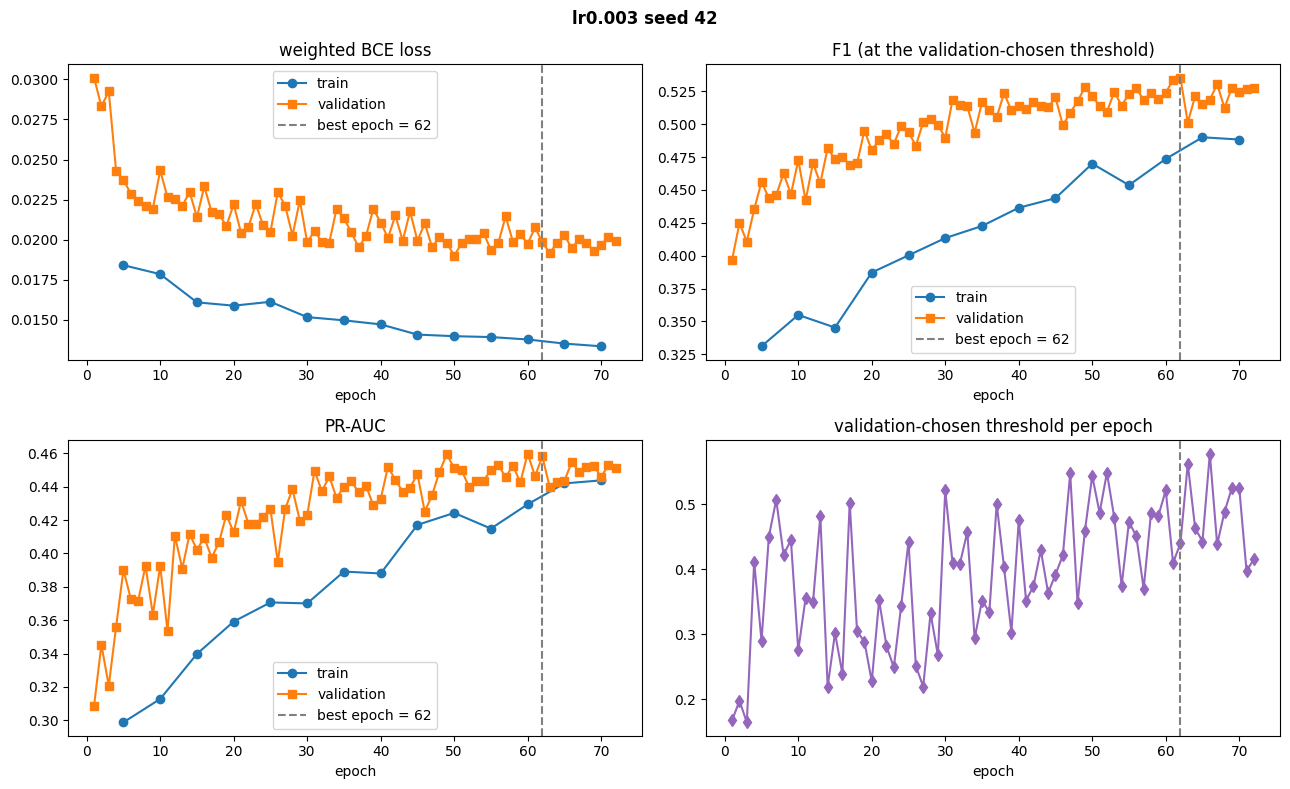

/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


predict train seed 42 @ epoch 61:   0%|          | 0/372 [00:00<?, ?it/s]

predict val seed 42 @ epoch 61:   0%|          | 0/124 [00:00<?, ?it/s]

trial lr0.003: best epoch 61 (seed-mean, smoothed) | val F1 0.5328 ± 0.0000 | train F1 0.4910 | gap -0.0419 | epochs run {'42': 72} | checkpoints deleted
winner: base (val F1 0.5488 ± 0.0000); incumbent base 0.5488 ± 0.0000
3 trials -> /kaggle/working/gnn_for_fraudulent_patterns/Outputs/TUNING/GAT/s6_lr/stage_summary.csv | train - val gap: validation has 0.107 % laundering vs 0.075 % on train, so part of the gap is prevalence, not underfitting
>>> after s6_lr: incumbent = base | best epoch 44 | {'hidden': 128, 'num_layers': 2, 'dropout': 0.3, 'norm': 'none', 'ffn': False, 'num_neighbors': [100, 100], 'batch_size': 8192, 'epochs': 100, 'lr': 0.001, 'weight_decay': 1e-05, 'pos_weight': 8.0, 'self_loops': True}
=== s7_dropout/d0.2 === recipe {'hidden': 128, 'num_layers': 2, 'dropout': 0.2, 'norm': 'none', 'ffn': False, 'num_neighbors': [100, 100], 'batch_size': 8192, 'epochs': 100, 'lr': 0.001, 'weight_decay': 1e-05, 'pos_weight': 8.0, 'self_loops': True}
=== d0.2 seed 42 ===
MP edge feat

/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


...

epoch 69 | loss   -    / 0.0193 | F1   -    / 0.5395 @ 0.528 | PR-AUC   -    / 0.4726 | 67s | RAM 7.6GB   (train / val)


train:   0%|          | 0/372 [00:00<?, ?it/s]

predict train:   0%|          | 0/372 [00:00<?, ?it/s]

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 70 | loss 0.0119 / 0.0193 | F1 0.5439 / 0.5397 @ 0.675 | PR-AUC 0.5151 / 0.4712 | 105s | RAM 7.6GB   (train / val)
early stop at epoch 70: smoothed val F1 has not improved for 10 epochs
best validation F1 0.5551 at epoch 62 (threshold 0.630) | 70 of 100 epochs run


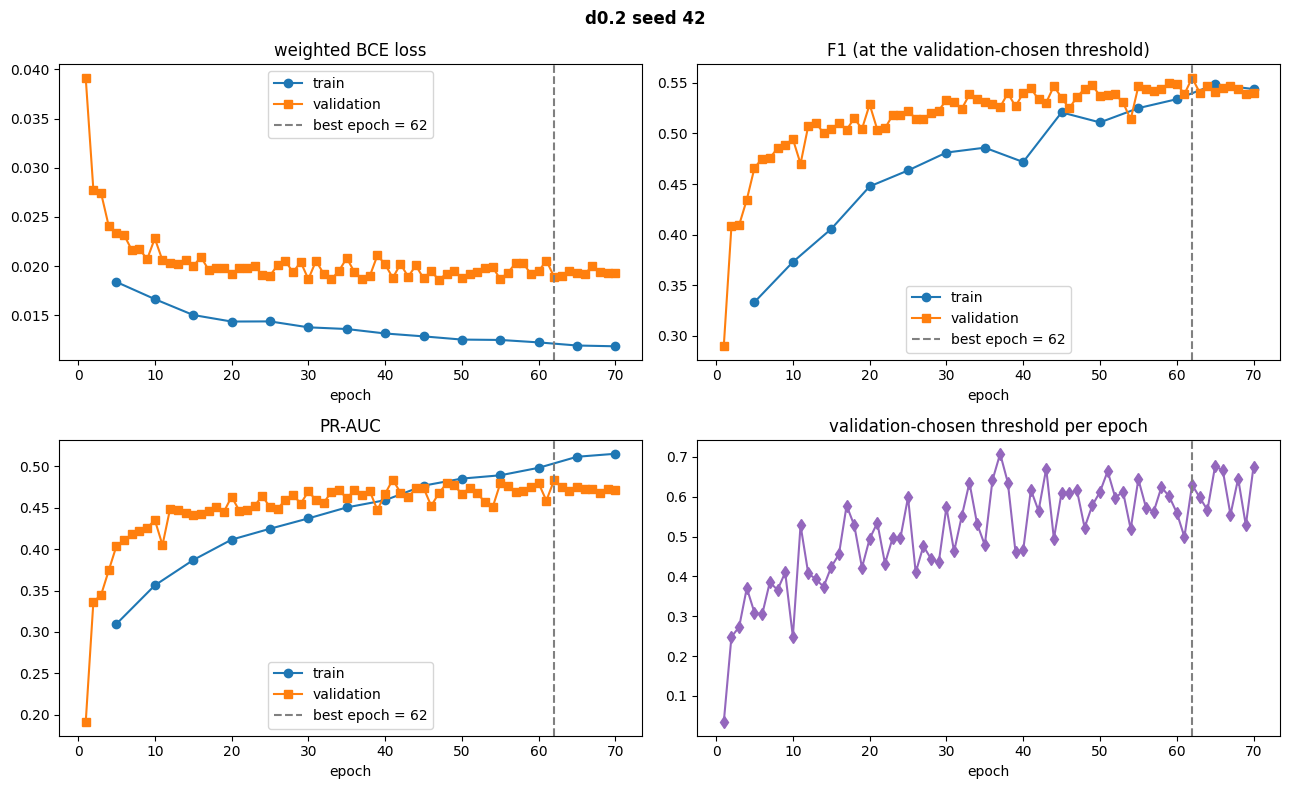

/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


predict train seed 42 @ epoch 61:   0%|          | 0/372 [00:00<?, ?it/s]

predict val seed 42 @ epoch 61:   0%|          | 0/124 [00:00<?, ?it/s]

trial d0.2: best epoch 61 (seed-mean, smoothed) | val F1 0.5380 ± 0.0000 | train F1 0.5337 | gap -0.0043 | epochs run {'42': 70} | checkpoints deleted
=== s7_dropout/base === same recipe as the incumbent s6_lr/base: scoring copied, not retrained
=== s7_dropout/d0.4 === recipe {'hidden': 128, 'num_layers': 2, 'dropout': 0.4, 'norm': 'none', 'ffn': False, 'num_neighbors': [100, 100], 'batch_size': 8192, 'epochs': 100, 'lr': 0.001, 'weight_decay': 1e-05, 'pos_weight': 8.0, 'self_loops': True}
=== d0.4 seed 42 ===
MP edge features: 20 | readout edge features: 20 | node features: 6
total params: 108,161 | architecture-invariant: 67,585


/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


...

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 67 | loss   -    / 0.0195 | F1   -    / 0.5371 @ 0.476 | PR-AUC   -    / 0.4640 | 67s | RAM 7.6GB   (train / val)   * new best -> best.pt


train:   0%|          | 0/372 [00:00<?, ?it/s]

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 68 | loss   -    / 0.0194 | F1   -    / 0.5214 @ 0.481 | PR-AUC   -    / 0.4524 | 66s | RAM 7.6GB   (train / val)
early stop at epoch 68: smoothed val F1 has not improved for 10 epochs
best validation F1 0.5371 at epoch 67 (threshold 0.476) | 68 of 100 epochs run


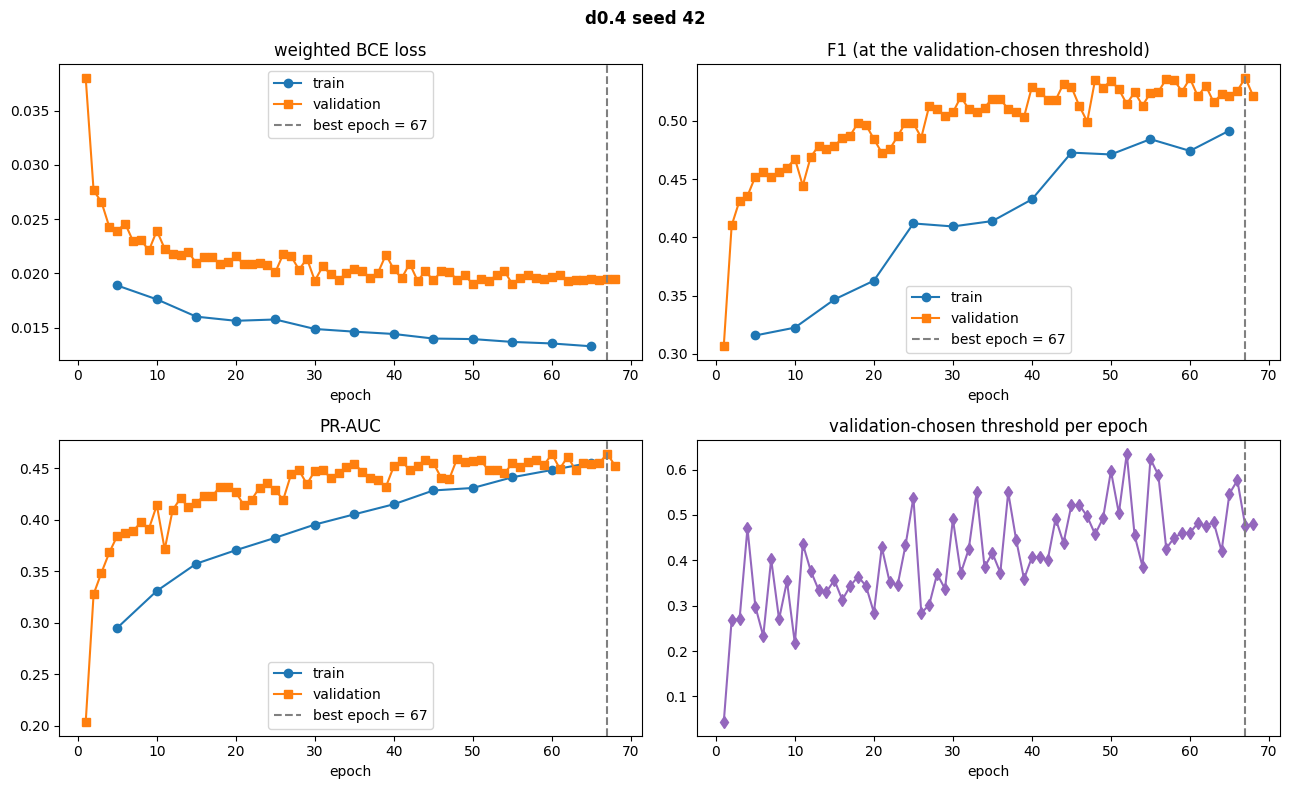

/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


predict train seed 42 @ epoch 49:   0%|          | 0/372 [00:00<?, ?it/s]

predict val seed 42 @ epoch 49:   0%|          | 0/124 [00:00<?, ?it/s]

trial d0.4: best epoch 49 (seed-mean, smoothed) | val F1 0.5277 ± 0.0000 | train F1 0.4754 | gap -0.0523 | epochs run {'42': 68} | checkpoints deleted
winner: base (val F1 0.5488 ± 0.0000); incumbent base 0.5488 ± 0.0000
3 trials -> /kaggle/working/gnn_for_fraudulent_patterns/Outputs/TUNING/GAT/s7_dropout/stage_summary.csv | train - val gap: validation has 0.107 % laundering vs 0.075 % on train, so part of the gap is prevalence, not underfitting
>>> after s7_dropout: incumbent = base | best epoch 44 | {'hidden': 128, 'num_layers': 2, 'dropout': 0.3, 'norm': 'none', 'ffn': False, 'num_neighbors': [100, 100], 'batch_size': 8192, 'epochs': 100, 'lr': 0.001, 'weight_decay': 1e-05, 'pos_weight': 8.0, 'self_loops': True}
all stages complete | incumbent: base {'hidden': 128, 'num_layers': 2, 'dropout': 0.3, 'norm': 'none', 'ffn': False, 'num_neighbors': [100, 100], 'batch_size': 8192, 'epochs': 100, 'lr': 0.001, 'weight_decay': 1e-05, 'pos_weight': 8.0, 'self_loops': True}


In [6]:
incumbent = core.full_recipe(TUNE)          # the v1 recipe + T_max 100; each stage may replace one knob
incumbent_trial, winners = None, {}
for stage, knob, grid in STAGES:
    stage_dir = f'{OUT_ROOT}/{stage}'
    os.makedirs(stage_dir, exist_ok=True)
    trials, recipes = [], {}
    for value in grid:
        recipe = core.with_knob(incumbent, knob, value, NEIGHBOURS_USED)
        if recipe is None:
            print(f'{stage}: {knob} = {value} skipped (depth dropped by the probe)')
            continue
        trial = core.run_tuning_trial(OPERATOR, CFG, graphs, col_sets, node_dim, stage_dir, recipe, SEEDS, TUNE,
                                      MP_DIRECTION, TEMPORAL_SAMPLING, EVAL_TRAIN_EVERY, PATIENCE, MIN_EPOCHS,
                                      reuse=incumbent_trial)
        trials.append(trial)
        recipes[trial['trial']] = recipe
    winner = core.choose_winner(trials, core.recipe_tag(incumbent, TUNE))

    # edge rule: a numeric winner at the edge of its grid gets one trial one step beyond
    beyond = core.edge_value(knob, winner['recipe'][knob], grid)
    if beyond is not None:
        if knob == 'num_layers' and beyond not in NEIGHBOURS_USED:
            extra_probe = core.probe_depths(OPERATOR, CFG, graphs, col_sets, node_dim, HEAVIEST, (beyond,),
                                            f'{OUT_ROOT}/probe_{beyond}L.json', mp_direction=MP_DIRECTION,
                                            temporal=TEMPORAL_SAMPLING, reference_seconds=probe['reference_seconds'])
            NEIGHBOURS_USED = core.neighbours_from_probe(extra_probe, NEIGHBOURS_USED)
        recipe = core.with_knob(winner['recipe'], knob, beyond, NEIGHBOURS_USED)
        if recipe is None:
            print(f'{stage}: edge trial {knob} = {beyond} skipped (depth failed the probe)')
        else:
            extra = core.run_tuning_trial(OPERATOR, CFG, graphs, col_sets, node_dim, stage_dir, recipe, SEEDS, TUNE,
                                          MP_DIRECTION, TEMPORAL_SAMPLING, EVAL_TRAIN_EVERY, PATIENCE, MIN_EPOCHS)
            trials.append(extra)
            recipes[extra['trial']] = recipe
            winner = core.choose_winner(trials, winner['trial'])

    incumbent, incumbent_trial, winners[stage] = recipes[winner['trial']], winner, winner['trial']
    core.summarize_stage(stage_dir, winner['trial'])
    print(f">>> after {stage}: incumbent = {winner['trial']} | best epoch {winner['best_epoch']} | {incumbent}")
print('=' * 90)
print('all stages complete | incumbent:', incumbent_trial['trial'], incumbent)

## 5. Summary across the stages

- `trials_summary.csv`: one row per trial with every knob, best / stopped epochs, train and validation F1 / PR-AUC (mean ± std), the train − val gap and the winner flag.
- Gap caveat: validation has 0.107 % laundering vs 0.075 % on train, so part of any gap is prevalence, not underfitting.
- `tuning_curves.png`: seed-mean validation F1 per epoch, one line per trial, winners bold.

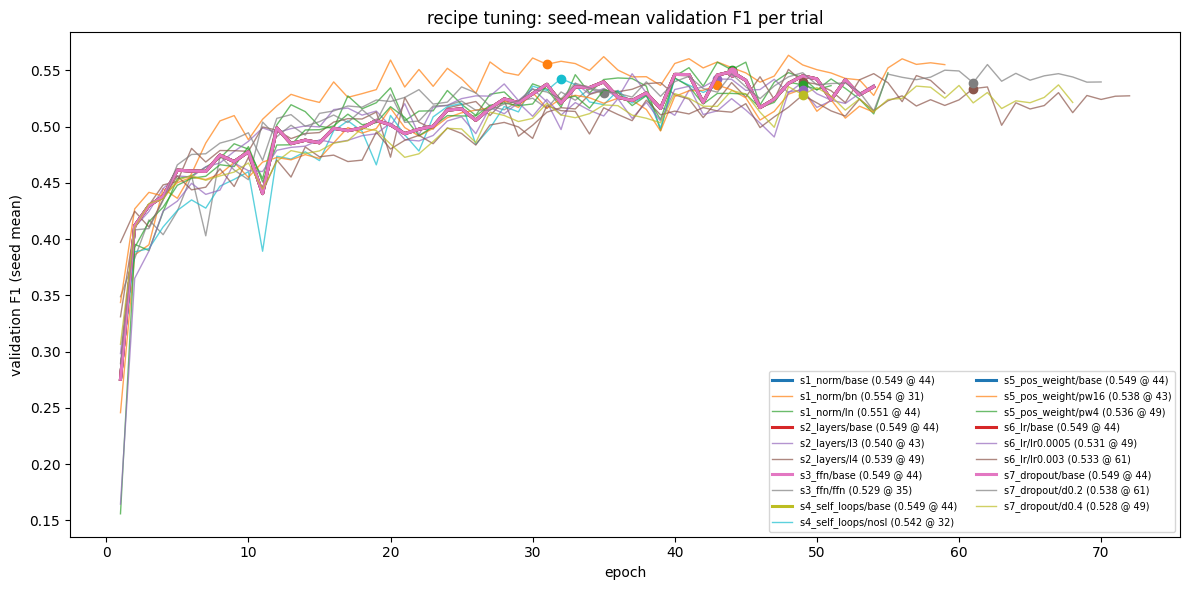

19 trials -> /kaggle/working/gnn_for_fraudulent_patterns/Outputs/TUNING/GAT/trials_summary.csv | train - val gap: validation has 0.107 % laundering vs 0.075 % on train, so part of the gap is prevalence, not underfitting


,stage,trial,winner,dropout,norm,num_layers,num_neighbors,pos_weight,lr,ffn,...,epochs_run,reached_max,val_f1_mean,val_f1_std,train_f1_mean,gap_f1,val_pr_auc_mean,thresholds,params,invariant_params
0,s1_norm,base,True,0.3,none,2,100-100,8.0,0.0010,False,...,54,False,0.5488,0.0,0.4856,-0.0632,0.4741,0.483,108161,67585
1,s1_norm,bn,False,0.3,batch,2,100-100,8.0,0.0010,False,...,59,False,0.5545,0.0,0.5011,-0.0534,0.4756,0.397,108673,68097
2,s1_norm,ln,False,0.3,layer,2,100-100,8.0,0.0010,False,...,55,False,0.5505,0.0,0.4877,-0.0628,0.4783,0.469,108673,68097
3,s2_layers,base,True,0.3,none,2,100-100,8.0,0.0010,False,...,54,False,0.5488,0.0,0.4856,-0.0632,0.4741,0.483,108161,67585
4,s2_layers,l3,False,0.3,none,3,100-100-50,8.0,0.0010,False,...,54,False,0.5395,0.0,0.4848,-0.0547,0.4754,0.543,144001,100865
5,s2_layers,l4,False,0.3,none,4,100-100-50-50,8.0,0.0010,False,...,59,False,0.5395,0.0,0.5124,-0.0271,0.4680,0.500,179841,134145
6,s3_ffn,base,True,0.3,none,2,100-100,8.0,0.0010,False,...,54,False,0.5488,0.0,0.4856,-0.0632,0.4741,0.483,108161,67585
7,s3_ffn,ffn,False,0.3,none,2,100-100,8.0,0.0010,True,...,36,False,0.5293,0.0,0.4670,-0.0623,0.4684,0.587,240513,199937
8,s4_self_loops,base,True,0.3,none,2,100-100,8.0,0.0010,False,...,54,False,0.5488,0.0,0.4856,-0.0632,0.4741,0.483,108161,67585
9,s4_self_loops,nosl,False,0.3,none,2,100-100,8.0,0.0010,False,...,43,False,0.5418,0.0,0.4782,-0.0636,0.4756,0.535,108161,67585


In [7]:
summary = core.summarize_tuning(OUT_ROOT, winners)
summary[['stage', 'trial', 'winner', 'dropout', 'norm', 'num_layers', 'num_neighbors', 'pos_weight', 'lr', 'ffn',
         'best_epoch', 'epochs_run', 'reached_max', 'val_f1_mean', 'val_f1_std', 'train_f1_mean', 'gap_f1',
         'val_pr_auc_mean', 'thresholds', 'params', 'invariant_params']].round(4)

## 6. Freeze the recipe

- Only after every stage has run: `recipe.json` = knobs, neighbour lists, T_max, best epoch, per-seed thresholds for the four retrain seeds (42 and 43 their own; 44 and 45 the mean of those two), the validation F1 that chose them.
- This file is the single source of the frozen GATv2 recipe; `GAT_tuning_final.ipynb` loads it.

In [8]:
assert set(winners) == {stage for stage, _, _ in STAGES}, 'run every stage before freezing the recipe'
frozen = core.save_recipe(f'{OUT_ROOT}/recipe.json', OPERATOR, CFG, incumbent_trial)

frozen recipe -> /kaggle/working/gnn_for_fraudulent_patterns/Outputs/TUNING/GAT/recipe.json
{
 "operator": "gat",
 "cfg": {
  "mp": "base",
  "readout": "base"
 },
 "recipe": {
  "hidden": 128,
  "num_layers": 2,
  "dropout": 0.3,
  "norm": "none",
  "ffn": false,
  "num_neighbors": [
   100,
   100
  ],
  "batch_size": 8192,
  "epochs": 100,
  "lr": 0.001,
  "weight_decay": 1e-05,
  "pos_weight": 8.0,
  "self_loops": true
 },
 "best_epoch": 44,
 "tuning_seeds": [
  42
 ],
 "retrain_seeds": [
  42,
  43,
  44,
  45
 ],
 "thresholds": {
  "42": 0.4832745492458343,
  "43": 0.4832745492458343,
  "44": 0.4832745492458343,
  "45": 0.4832745492458343
 },
 "tuning_thresholds": {
  "42": 0.4832745492458343
 },
 "threshold_source": "one threshold for every retrain seed: the mean of the tuning seeds' validation thresholds at best_epoch",
 "val_f1_mean": 0.5488257107540173,
 "val_f1_std": 0.0,
 "train_f1_mean": 0.4856410256410256,
 "epochs_run": {
  "42": 54
 },
 "source_stage": "s7_dropout",
 "s

## 7. Download

- Zip `OUT_ROOT`; extract into `Outputs/TUNING/GAT/` in the repo and commit the small files (`trial.json`, `history.csv`, `curves.png`, summaries, `probe.json`, `recipe.json`; `best.pt` stays out of git).

In [9]:
import shutil
shutil.make_archive('/kaggle/working/Outputs_TUNING_GAT', 'zip', OUT_ROOT)

'/kaggle/working/Outputs_TUNING_GAT.zip'